# Breast Cancer Wisconsin (Diagnostic) — Classification Assignment

**Source:** UCI Machine Learning Repository. This notebook compares Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and SVM.

It validates the data, explores class balance/correlations, creates a stratified train/test split, evaluates all six required metrics, and exports fitted model pipelines and labelled test data for the Streamlit app.

## 1. Imports

In [1]:
import json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.base import clone

RANDOM_STATE = 42
TEST_SIZE = 0.20
pd.set_option("display.max_columns", 40)
print("Imports complete.")

Imports complete.


## 2. Upload the prepared CSV
Download `breast_cancer_wisconsin_diagnostic.csv` from this conversation, then run the cell and select it.

In [2]:
df=pd.read_csv("breast_cancer_wisconsin_diagnostic.csv")
print("Loaded:", df.shape)
display(df.head())

Loaded: (569, 32)


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Validate dataset structure and quality

In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.info()
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("\nDiagnosis counts:")
display(df["Diagnosis"].value_counts(dropna=False).to_frame("count"))
print("\nDiagnosis percentages:")
display((df["Diagnosis"].value_counts(normalize=True, dropna=False)*100).round(2).to_frame("percent"))

Shape: (569, 32)

Columns: ['ID', 'Diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null  

,missing_values
ID,0
Diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave_points_mean,0


Exact duplicate rows: 0

Diagnosis counts:


,count
Diagnosis,
B,357
M,212



Diagnosis percentages:


,percent
Diagnosis,
B,62.74
M,37.26


## 4. Explore class balance and correlations
The original dataset should contain 569 records, 30 numeric predictors, an ID column, and the `Diagnosis` target. We exclude ID from modelling. Correlation is investigated, but predictors are not automatically removed just because they are correlated.

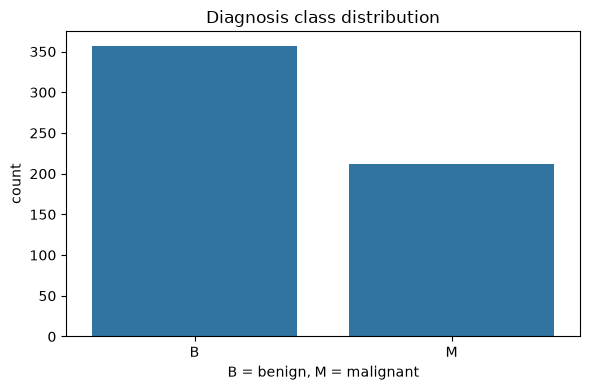

In [4]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Diagnosis", order=sorted(df["Diagnosis"].dropna().unique()))
plt.title("Diagnosis class distribution")
plt.xlabel("B = benign, M = malignant")
plt.tight_layout()
plt.show()

Numeric candidate predictors: 30


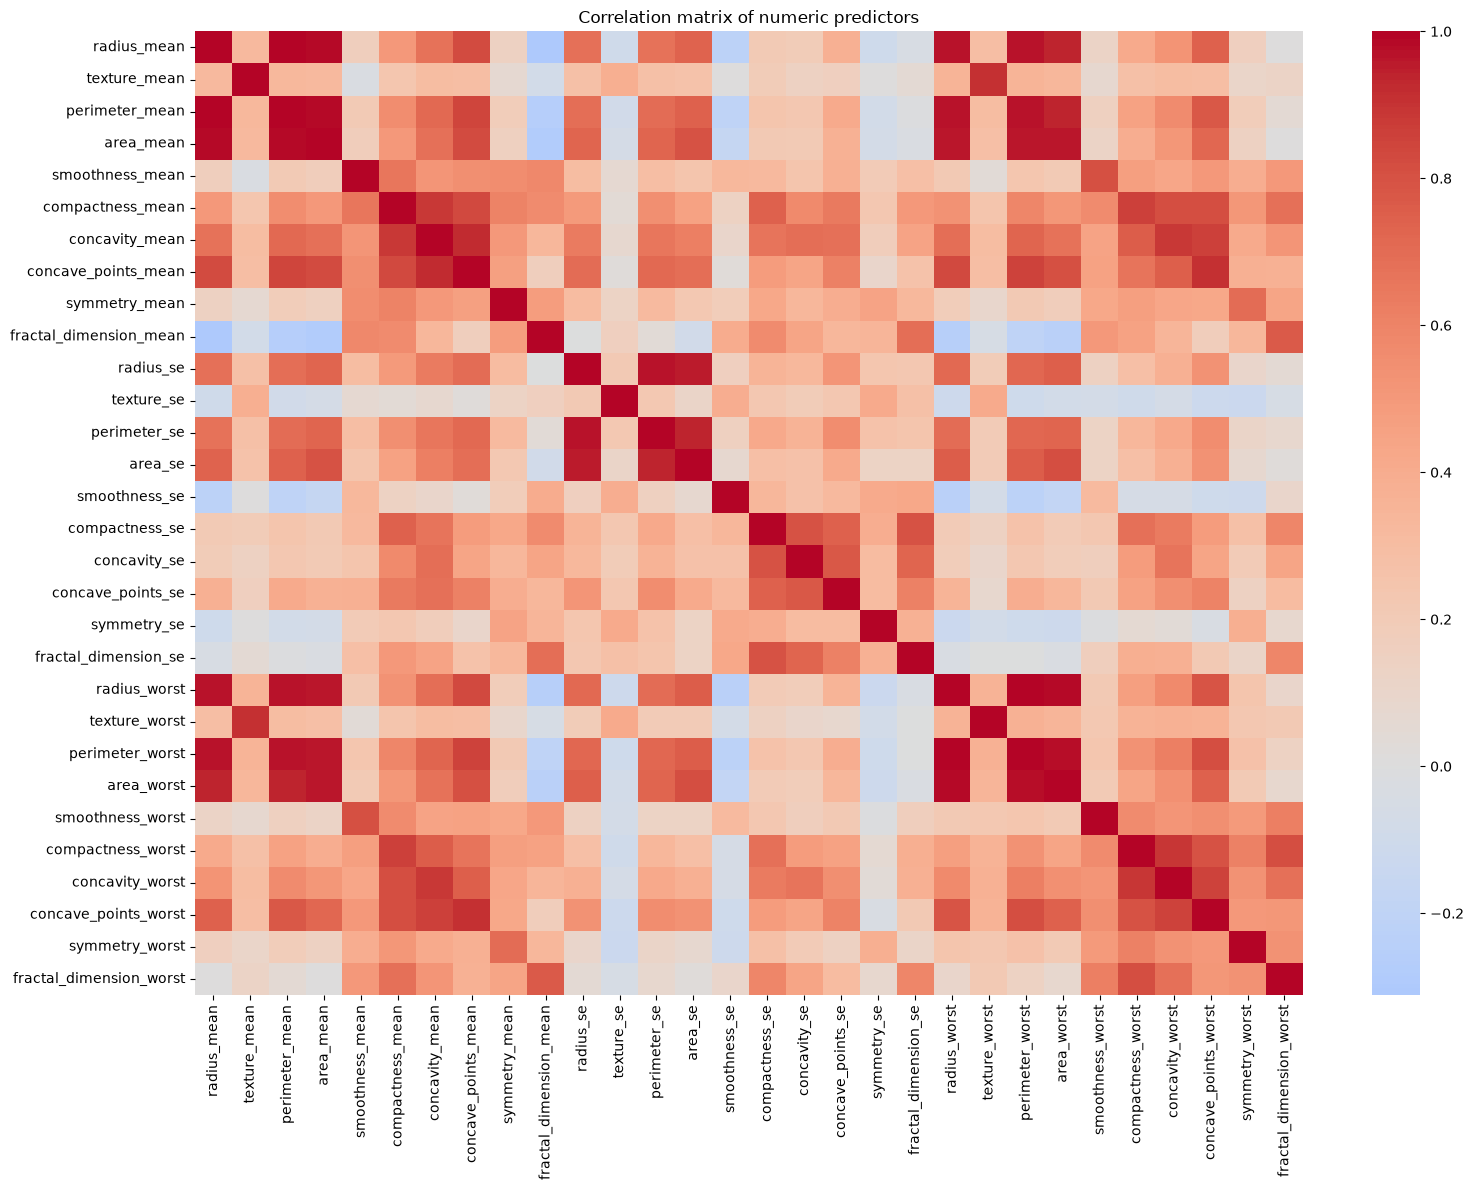

,Feature_1,Feature_2,Absolute_Correlation
60,perimeter_mean,radius_mean,0.997855
680,perimeter_worst,radius_worst,0.993708
90,area_mean,radius_mean,0.987357
92,area_mean,perimeter_mean,0.986507
710,area_worst,radius_worst,0.984015
712,area_worst,perimeter_worst,0.977578
370,perimeter_se,radius_se,0.972794
82,perimeter_mean,perimeter_worst,0.970387
20,radius_mean,radius_worst,0.969539
80,perimeter_mean,radius_worst,0.969476


In [5]:
eda_features = [c for c in df.columns if c not in ["ID", "Diagnosis"] and pd.api.types.is_numeric_dtype(df[c])]
print("Numeric candidate predictors:", len(eda_features))
corr = df[eda_features].corr()
plt.figure(figsize=(16,12))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix of numeric predictors")
plt.tight_layout()
plt.show()

corr_abs = corr.abs().where(~np.eye(corr.shape[0], dtype=bool))
pairs = corr_abs.stack().reset_index()
pairs.columns = ["Feature_1", "Feature_2", "Absolute_Correlation"]
pairs = pairs[pairs["Feature_1"] < pairs["Feature_2"]].sort_values("Absolute_Correlation", ascending=False)
display(pairs.head(15))

## 5. Prepare features and target
Encode malignant (`M`) as 1 and benign (`B`) as 0. Exclude `ID` and `Diagnosis` from predictors. Retain the 30 measurement features, comfortably meeting the minimum of 12 input features. The split is stratified; preprocessing is fitted inside pipelines on training data only.

In [6]:
df.columns = df.columns.astype(str).str.strip()
df = df.dropna(subset=["Diagnosis"]).copy()
df["Diagnosis"] = df["Diagnosis"].astype(str).str.strip().str.upper()
labels = set(df["Diagnosis"].unique())
if not labels.issubset({"B", "M"}):
    raise ValueError(f"Unexpected Diagnosis labels: {labels}; expected B and M.")

y = df["Diagnosis"].map({"B": 0, "M": 1}).astype(int)
excluded = ["Diagnosis"] + (["ID"] if "ID" in df.columns else [])
X = df.drop(columns=excluded).copy()
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    X = X.drop(columns=all_missing)
if X.shape[1] < 12:
    raise ValueError(f"Only {X.shape[1]} predictors remain; at least 12 are required.")

feature_names = X.columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Predictors:", len(feature_names))
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTraining class proportions (%):")
display(y_train.map({0:"Benign (B)",1:"Malignant (M)"}).value_counts(normalize=True).mul(100).round(2).to_frame("percent"))
print("\nTest class proportions (%):")
display(y_test.map({0:"Benign (B)",1:"Malignant (M)"}).value_counts(normalize=True).mul(100).round(2).to_frame("percent"))

Predictors: 30
Train: (455, 30) | Test: (114, 30)

Training class proportions (%):


,percent
Diagnosis,
Benign (B),62.64
Malignant (M),37.36



Test class proportions (%):


,percent
Diagnosis,
Benign (B),63.16
Malignant (M),36.84


Let us apply class balance to control the model drifting towards the majority class

In [7]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before oversampling
print("Before oversampling:", Counter(y_train))

# Apply SMOTE to the training data only
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train, y_train
)

# Check class distribution after oversampling
print("After oversampling:", Counter(y_train_resampled))

print("Original training shape:", X_train.shape)
print("Resampled training shape:", X_train_resampled.shape)

Before oversampling: Counter({0: 285, 1: 170})
After oversampling: Counter({1: 285, 0: 285})
Original training shape: (455, 30)
Resampled training shape: (570, 30)


## 6. Configure the five classifiers
Scaling is included for Logistic Regression, KNN, and SVM. The imputer is included defensively and is fitted only on training data.

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=RANDOM_STATE))
    ])
}
print("Configured:", ", ".join(models.keys()))

Configured: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM


## 7. Train and evaluate
For Precision, Recall, and F1, malignant (`M`, encoded as 1) is the positive class. AUC is calculated from predicted probabilities.

In [9]:
fitted_models, predictions, probabilities, results = {}, {}, {}, []
for name, pipeline in models.items():
    model = clone(pipeline)
    model.fit(X_train_resampled, y_train_resampled)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    fitted_models[name] = model
    predictions[name] = pred
    probabilities[name] = prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred)
    })
results_df = pd.DataFrame(results).sort_values("AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))

c:\Users\mvsla\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.9825,0.9947,0.9762,0.9762,0.9762,0.9623
1,Gaussian Naive Bayes,0.9298,0.9947,0.9722,0.8333,0.8974,0.8504
2,Logistic Regression,0.9737,0.9944,0.9756,0.9524,0.9639,0.9433
3,KNN,0.9561,0.9836,0.9744,0.9048,0.9383,0.9058
4,Decision Tree,0.9211,0.9127,0.9024,0.8810,0.8916,0.8297


## 8. Confusion matrices and classification reports
False negatives are malignant cases predicted as benign. Discuss these errors carefully, but do not interpret this educational model as medical advice.


Logistic Regression
               precision    recall  f1-score   support

   Benign (B)     0.9726    0.9861    0.9793        72
Malignant (M)     0.9756    0.9524    0.9639        42

     accuracy                         0.9737       114
    macro avg     0.9741    0.9692    0.9716       114
 weighted avg     0.9737    0.9737    0.9736       114



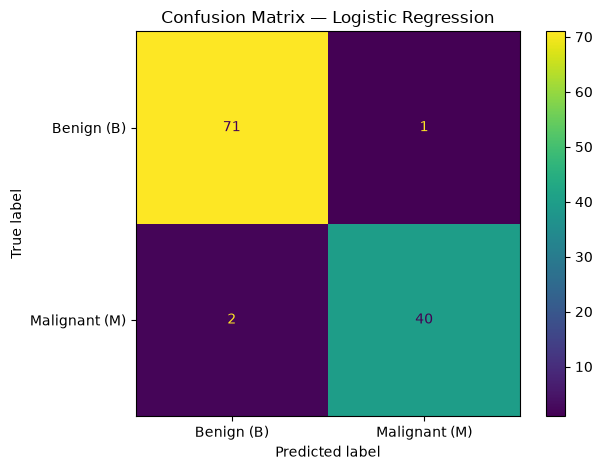


Decision Tree
               precision    recall  f1-score   support

   Benign (B)     0.9315    0.9444    0.9379        72
Malignant (M)     0.9024    0.8810    0.8916        42

     accuracy                         0.9211       114
    macro avg     0.9170    0.9127    0.9147       114
 weighted avg     0.9208    0.9211    0.9208       114



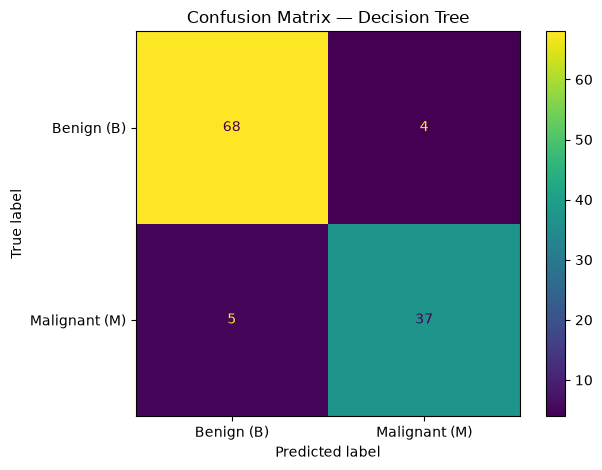


KNN
               precision    recall  f1-score   support

   Benign (B)     0.9467    0.9861    0.9660        72
Malignant (M)     0.9744    0.9048    0.9383        42

     accuracy                         0.9561       114
    macro avg     0.9605    0.9454    0.9521       114
 weighted avg     0.9569    0.9561    0.9558       114



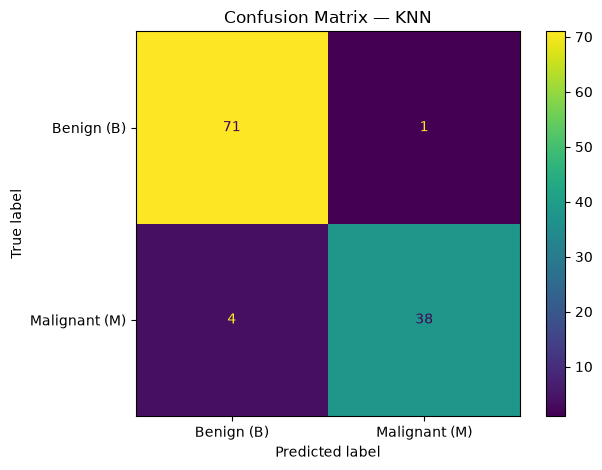


Gaussian Naive Bayes
               precision    recall  f1-score   support

   Benign (B)     0.9103    0.9861    0.9467        72
Malignant (M)     0.9722    0.8333    0.8974        42

     accuracy                         0.9298       114
    macro avg     0.9412    0.9097    0.9221       114
 weighted avg     0.9331    0.9298    0.9285       114



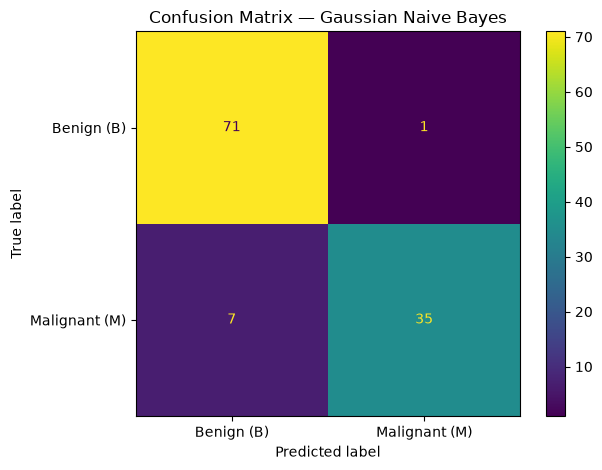


SVM
               precision    recall  f1-score   support

   Benign (B)     0.9861    0.9861    0.9861        72
Malignant (M)     0.9762    0.9762    0.9762        42

     accuracy                         0.9825       114
    macro avg     0.9812    0.9812    0.9812       114
 weighted avg     0.9825    0.9825    0.9825       114



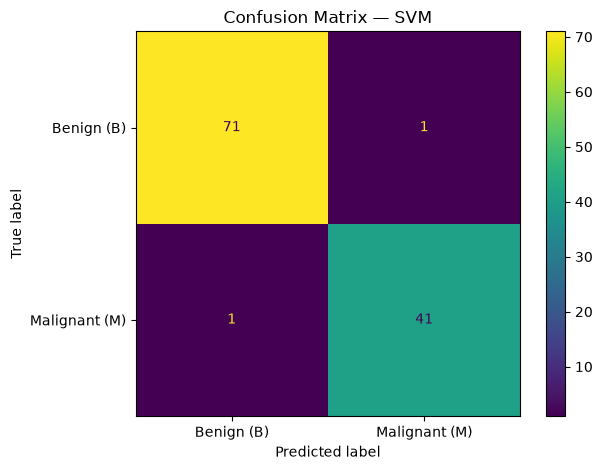

In [10]:
for name, pred in predictions.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")
    print(classification_report(
        y_test, pred, labels=[0,1],
        target_names=["Benign (B)", "Malignant (M)"],
        zero_division=0, digits=4
    ))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, pred, labels=[0,1]),
        display_labels=["Benign (B)", "Malignant (M)"]
    )
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 9. ROC curves and metric comparison

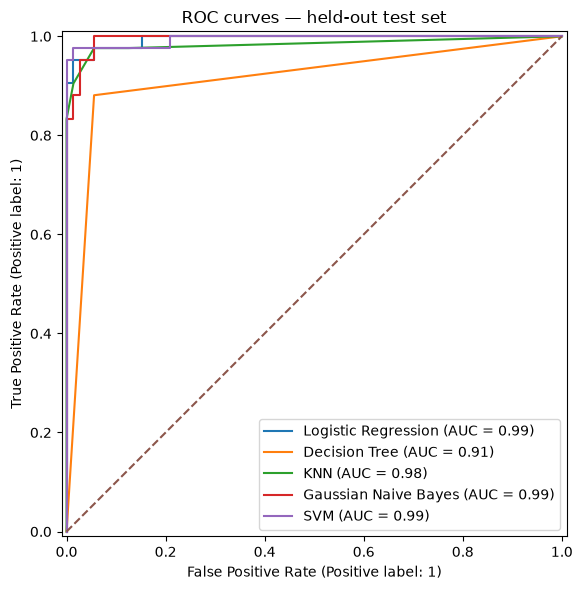

In [11]:
fig, ax = plt.subplots(figsize=(8,6))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0,1], [0,1], linestyle="--", label="Chance")
ax.set_title("ROC curves — held-out test set")
plt.tight_layout()
plt.show()

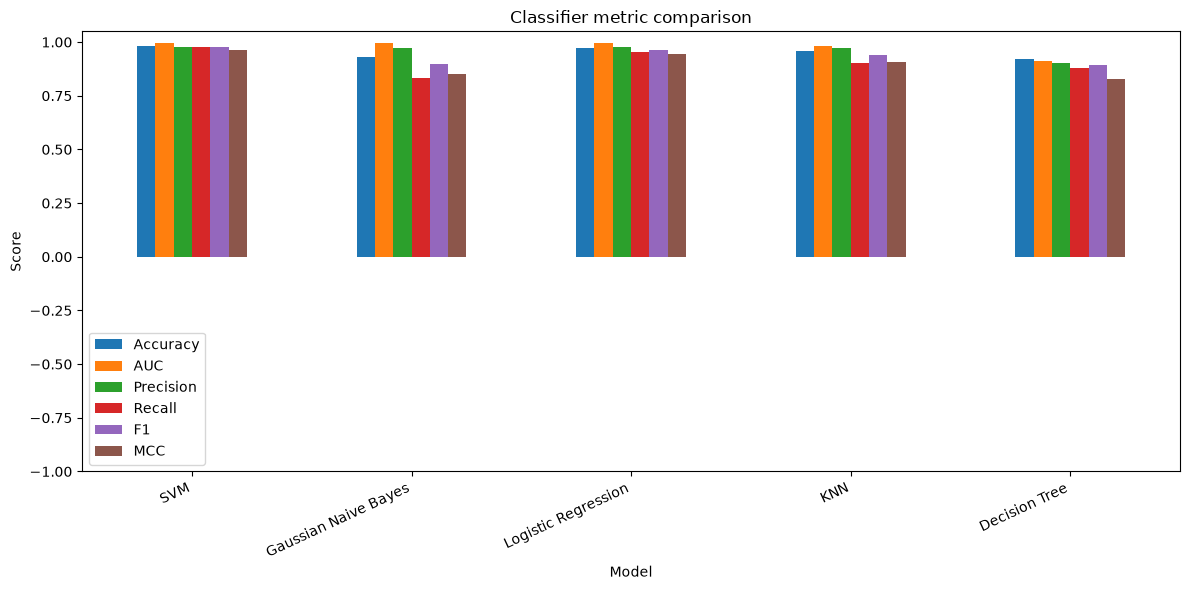

In [12]:
metric_cols = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
results_df.set_index("Model")[metric_cols].plot(kind="bar", figsize=(12,6), ylim=(-1,1.05))
plt.title("Classifier metric comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 10. Results observations
Use the actual output from your run to write the README. Highest AUC is one comparison criterion, not an automatic universal winner; discuss Recall, Precision, F1, MCC, and confusion matrices too.

In [13]:
print("Highest AUC:", results_df.loc[results_df["AUC"].idxmax(), "Model"])
print("Highest F1:", results_df.loc[results_df["F1"].idxmax(), "Model"])
print("Highest malignant-class Recall:", results_df.loc[results_df["Recall"].idxmax(), "Model"])

Highest AUC: SVM
Highest F1: SVM
Highest malignant-class Recall: SVM


## 11. Save fitted model pipelines and metrics
Each saved pipeline includes preprocessing plus its classifier. The Streamlit app should load these files and evaluate uploaded labelled test data; it must not retrain on uploaded data.

In [14]:
model_dir = Path("model")
model_dir.mkdir(exist_ok=True)
metadata = {
    "dataset": "UCI Breast Cancer Wisconsin (Diagnostic)",
    "target_column": "Diagnosis",
    "target_mapping": {"B": 0, "M": 1},
    "positive_class": "M (malignant)",
    "feature_columns": feature_names,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE
}
(model_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_nb.joblib",
    "SVM": "svm.joblib"
}
for name, model in fitted_models.items():
    joblib.dump(model, model_dir / model_files[name])
results_df.to_csv("model_comparison_metrics.csv", index=False)
print("Saved models:")
for p in sorted(model_dir.iterdir()):
    print("-", p)

Saved models:
- model\decision_tree.joblib
- model\gaussian_nb.joblib
- model\knn.joblib
- model\logistic_regression.joblib
- model\metadata.json
- model\svm.joblib


## 12. Export held-out test data
The assignment requires a test CSV with input features and target. This exports held-out rows only. Do not use these rows to train or tune the saved models.

In [15]:
test_data = X_test.copy()
test_data["Diagnosis"] = y_test.map({0:"B", 1:"M"}).values
test_data.to_csv("test_data.csv", index=False)
print("Created test_data.csv with shape:", test_data.shape)
display(test_data.head())

Created test_data.csv with shape: (114, 31)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,Diagnosis
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,0.1408,0.4607,1.103,10.50,0.006040,0.01529,0.015140,0.006460,0.01344,0.002206,12.82,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523,B
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,1.0040,0.8208,6.372,137.90,0.005283,0.03908,0.095180,0.018640,0.02401,0.005002,25.58,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849,M
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,0.1745,0.4890,1.349,14.91,0.004510,0.01812,0.019510,0.011960,0.01934,0.003696,16.97,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960,B
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,0.2895,1.8510,2.376,26.85,0.008005,0.02895,0.033210,0.014240,0.01462,0.004452,16.33,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353,M
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,0.3408,1.9240,2.287,28.93,0.005841,0.01246,0.007936,0.009128,0.01564,0.002985,15.05,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675,B


## 13. Package and download artifacts

In [16]:
shutil.make_archive("model", "zip", root_dir=model_dir)
print("Created model.zip, test_data.csv, and model_comparison_metrics.csv")

Created model.zip, test_data.csv, and model_comparison_metrics.csv
